In [3]:
# PART 1: DATA PREPROCESSING & FEATURE SELECTION


#Install & Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [4]:
#Load the Dataset

df = pd.read_csv('6FTC2088-1.csv')

print(f"Dataset shape: {df.shape}")  # Should be (2764, 22)
print(df.head())

Dataset shape: (2764, 22)
         Date   Time  CO2_room  Relative_humidity_room  Lighting_room  \
0  13/03/2012  11:45   221.920                 42.4150        113.520   
1  13/03/2012  12:00   220.363                 42.2453        113.605   
2  13/03/2012  12:15   218.933                 42.2267        113.600   
3  13/03/2012  12:30   217.045                 42.0987        113.344   
4  13/03/2012  12:45   216.080                 42.0686        113.034   

   Meteo_Rain  Meteo_Sun_dusk  Meteo_Wind  Meteo_Sun_light_in_west_facade  \
0         0.0         623.360     1.42625                               0   
1         0.0         623.211     1.59200                               0   
2         0.0         622.656     1.89133                               0   
3         0.0         622.571     1.82800                               0   
4         0.0         622.400     2.36071                               0   

   Meteo_Sun_light_in_east_facade  ...  Meteo_Sun_irradiance  \
0       

In [5]:
#Parse DateTime & Sort

# Combine Date and Time into a single datetime column
# This is important so the model understands the time order of readings
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], dayfirst=True)

# Set it as the index so the data is time-indexed
df = df.set_index('Datetime')

# Drop the original Date and Time columns (now redundant)
df = df.drop(columns=['Date', 'Time'])

# Sort by time just in case readings are out of order
df = df.sort_index()

print("Datetime index set.")
print(df.index[:5])

Datetime index set.
DatetimeIndex(['2012-03-13 11:45:00', '2012-03-13 12:00:00',
               '2012-03-13 12:15:00', '2012-03-13 12:30:00',
               '2012-03-13 12:45:00'],
              dtype='datetime64[ns]', name='Datetime', freq=None)


In [6]:
# Handle Missing Values

# Check how many values are missing per column
print("Missing values per column:")
print(df.isnull().sum())

# 'Outside temp' has 2 missing values — fill with forward fill
# (use the previous reading, which makes sense for temperature)
df['Outside temp'] = df['Outside temp'].fillna(method='ffill')

# 'Satisfaction' has 5 missing values and is a string (non-numeric)
# We will drop it as it is not used as a prediction target or input feature
df = df.drop(columns=['Satisfaction'], errors='ignore')

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values per column:
CO2_room                            0
Relative_humidity_room              0
Lighting_room                       0
Meteo_Rain                          0
Meteo_Sun_dusk                      0
Meteo_Wind                          0
Meteo_Sun_light_in_west_facade      0
Meteo_Sun_light_in_east_facade      0
Meteo_Sun_light_in_south_facade     0
Meteo_Sun_light_in_north_facade     0
Meteo_Sun_irradiance                0
Outdoor_relative_humidity_Sensor    0
Day_of_the_week                     0
Occupancy 1                         0
Occupancy 2                         0
Occupancy 3                         0
Indoor_temperature_room             0
Humidity                            0
Outside temp                        2
Satisfaction                        5
dtype: int64

Missing values after cleaning:
CO2_room                            0
Relative_humidity_room              0
Lighting_room                       0
Meteo_Rain                          0
Meteo_Sun_dusk  

/tmp/ipykernel_3463/128724437.py:9: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['Outside temp'] = df['Outside temp'].fillna(method='ffill')


In [7]:
# Feature Selection

# Our prediction targets are:
#   - Indoor_temperature_room
#   - Humidity

# We select features that are physically meaningful for predicting
# indoor temperature and humidity:

selected_features = [
    'CO2_room',                        # CO2 correlates with occupancy & ventilation
    'Relative_humidity_room',          # Current humidity affects future humidity
    'Meteo_Rain',                      # Rain affects outdoor conditions
    'Meteo_Wind',                      # Wind affects heat loss through walls
    'Meteo_Sun_irradiance',            # Solar radiation heats the room
    'Outdoor_relative_humidity_Sensor',# Outdoor humidity affects indoor humidity
    'Day_of_the_week',                 # Behavioural patterns differ on weekdays/weekends
    'Occupancy 1',                     # Occupants generate heat and CO2
    'Occupancy 2',
    'Occupancy 3',
    'Indoor_temperature_room',         # Current temp needed to predict next temp
    'Outside temp',                    # Outdoor temp directly affects indoor temp
    'Humidity'                         # Current humidity needed to predict next humidity
]

# Keep only selected features
df = df[selected_features]

print(f"Selected {len(selected_features)} features.")
print(df.head())

Selected 13 features.
                     CO2_room  Relative_humidity_room  Meteo_Rain  Meteo_Wind  \
Datetime                                                                        
2012-03-13 11:45:00   221.920                 42.4150         0.0     1.42625   
2012-03-13 12:00:00   220.363                 42.2453         0.0     1.59200   
2012-03-13 12:15:00   218.933                 42.2267         0.0     1.89133   
2012-03-13 12:30:00   217.045                 42.0987         0.0     1.82800   
2012-03-13 12:45:00   216.080                 42.0686         0.0     2.36071   

                     Meteo_Sun_irradiance  Outdoor_relative_humidity_Sensor  \
Datetime                                                                      
2012-03-13 11:45:00               758.880                           48.3750   
2012-03-13 12:00:00               762.069                           47.8080   
2012-03-13 12:15:00               766.251                           47.4320   
2012-03-13 12:3

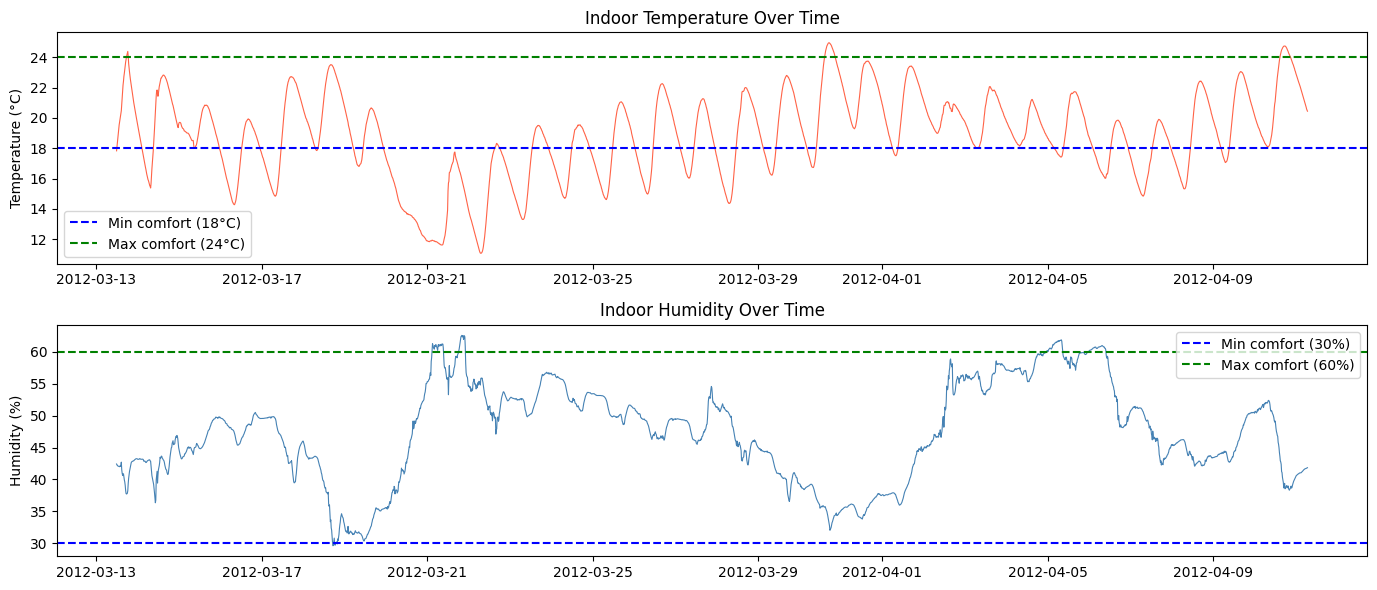

Plot saved.


In [8]:
# Visualise the Targets

# Plot indoor temperature and humidity over time

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

axes[0].plot(df['Indoor_temperature_room'], color='tomato', linewidth=0.8)
axes[0].set_title('Indoor Temperature Over Time')
axes[0].set_ylabel('Temperature (°C)')
axes[0].axhline(y=18, color='blue', linestyle='--', label='Min comfort (18°C)')
axes[0].axhline(y=24, color='green', linestyle='--', label='Max comfort (24°C)')
axes[0].legend()

axes[1].plot(df['Humidity'], color='steelblue', linewidth=0.8)
axes[1].set_title('Indoor Humidity Over Time')
axes[1].set_ylabel('Humidity (%)')
axes[1].axhline(y=30, color='blue', linestyle='--', label='Min comfort (30%)')
axes[1].axhline(y=60, color='green', linestyle='--', label='Max comfort (60%)')
axes[1].legend()

plt.tight_layout()
plt.savefig('targets_over_time.png', dpi=150)
plt.show()
print("Plot saved.")

In [9]:
# Normalise the Data

# Neural networks (RNN, LSTM, GRU) work much better when all input value
# are on the same scale. MinMaxScaler rescales everything to [0, 1].

scaler = MinMaxScaler()

# Fit the scaler on the full dataset and transform
df_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)

print("Data scaled to [0, 1] range.")
print(df_scaled.describe().round(3))

Data scaled to [0, 1] range.
       CO2_room  Relative_humidity_room  Meteo_Rain  Meteo_Wind  \
count  2764.000                2764.000    2764.000    2764.000   
mean      0.053                   0.537       0.047       0.175   
std       0.068                   0.229       0.207       0.184   
min       0.000                   0.000       0.000       0.000   
25%       0.033                   0.392       0.000       0.015   
50%       0.049                   0.544       0.000       0.104   
75%       0.058                   0.700       0.000       0.312   
max       1.000                   1.000       1.000       1.000   

       Meteo_Sun_irradiance  Outdoor_relative_humidity_Sensor  \
count              2764.000                          2764.000   
mean                  0.212                             0.548   
std                   0.288                             0.212   
min                   0.000                             0.000   
25%                   0.001               

In [10]:
# Create Time-Series Sequences

# For RNN/LSTM/GRU, we need to convert the data into sequences.
# Each input X is a window of the last `window_size` timesteps,
# and each output y is the next timestep's temperature and humidity.

WINDOW_SIZE = 10  # Use the last 10 readings (= 2.5 hours) to predict the next

def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        # Input: all features for the last `window_size` timesteps
        X.append(data[i : i + window_size])
        # Target: indoor temperature and humidity at the NEXT timestep
        y.append(data[i + window_size, [-2, -1]])  # last 2 cols = temp, humidity
    return np.array(X), np.array(y)

# Convert scaled dataframe to numpy array
data_array = df_scaled.values

X, y = create_sequences(data_array, WINDOW_SIZE)

print(f"X shape: {X.shape}")  # (samples, window_size, features)
print(f"y shape: {y.shape}")  # (samples, 2) — temperature & humidity

X shape: (2754, 10, 13)
y shape: (2754, 2)


In [11]:
#Train/Test Split

# We use 80% of data for training and 20% for testing.
# shuffle=False is criticial for time-series — we must not mix future data into training.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")

# Also prepare flat (2D) versions for Linear Regression
# Linear Regression can't handle 3D sequences, so we flatten the window
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat  = X_test.reshape(X_test.shape[0], -1)

print(f"\nFlat X_train shape (for Linear Regression): {X_train_flat.shape}")

Training samples: 2203
Testing samples:  551

Flat X_train shape (for Linear Regression): (2203, 130)


In [12]:
# PART 2: LINEAR REGRESSION MODEL

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

In [13]:
# Train the Linear Regression Model

# Linear Regression expects flat 2D input: (samples, features)
# We already prepared X_train_flat and X_test_flat in Part 1

lr_model = LinearRegression()
lr_model.fit(X_train_flat, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [14]:
# Make Predictions
# Predict on the test set
lr_predictions = lr_model.predict(X_test_flat)

# lr_predictions has shape (551, 2)
# Column 0 = predicted indoor temperature (scaled)
# Column 1 = predicted humidity (scaled)

print(f"Predictions shape: {lr_predictions.shape}")

Predictions shape: (551, 2)


In [15]:
# Evaluate the Mode

# We evaluate separately for temperature and humidity

# Temperature metrics
mae_temp  = mean_absolute_error(y_test[:, 0], lr_predictions[:, 0])
rmse_temp = np.sqrt(mean_squared_error(y_test[:, 0], lr_predictions[:, 0]))
r2_temp   = r2_score(y_test[:, 0], lr_predictions[:, 0])

# Humidity metrics
mae_hum  = mean_absolute_error(y_test[:, 1], lr_predictions[:, 1])
rmse_hum = np.sqrt(mean_squared_error(y_test[:, 1], lr_predictions[:, 1]))
r2_hum   = r2_score(y_test[:, 1], lr_predictions[:, 1])

print("=== Linear Regression Results (scaled values) ===")
print(f"Temperature — MAE: {mae_temp:.4f} | RMSE: {rmse_temp:.4f} | R²: {r2_temp:.4f}")
print(f"Humidity    — MAE: {mae_hum:.4f}  | RMSE: {rmse_hum:.4f}  | R²: {r2_hum:.4f}")

# Store results for later comparison in Part 5
lr_results = {
    'Model': 'Linear Regression',
    'Temp MAE': mae_temp, 'Temp RMSE': rmse_temp, 'Temp R2': r2_temp,
    'Hum MAE': mae_hum,   'Hum RMSE': rmse_hum,   'Hum R2': r2_hum
}

=== Linear Regression Results (scaled values) ===
Temperature — MAE: 0.0047 | RMSE: 0.0656 | R²: -1.3513
Humidity    — MAE: 0.0224  | RMSE: 0.1571  | R²: 0.3175


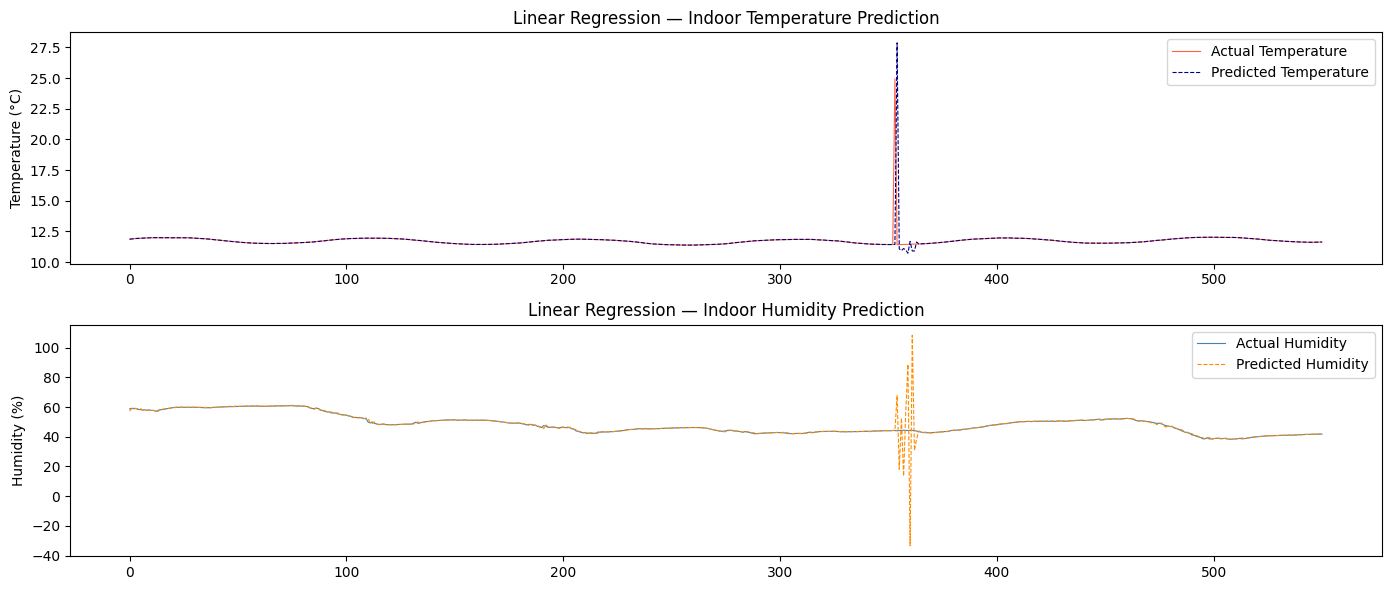

In [16]:
# Plot Predictions vs Actual

# Use the min/max from the CLEANED dataset (after outlier removal)
# not the original file, to ensure correct inverse scaling

temp_min = df['Indoor_temperature_room'].min()
temp_max = df['Indoor_temperature_room'].max()
hum_min  = df['Humidity'].min()
hum_max  = df['Humidity'].max()

# Manually reverse the MinMax scaling: original = scaled * (max - min) + min
pred_temp = lr_predictions[:, 0] * (temp_max - temp_min) + temp_min
pred_hum  = lr_predictions[:, 1] * (hum_max  - hum_min)  + hum_min
true_temp = y_test[:, 0] * (temp_max - temp_min) + temp_min
true_hum  = y_test[:, 1] * (hum_max  - hum_min)  + hum_min

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

axes[0].plot(true_temp, label='Actual Temperature', color='tomato', linewidth=0.8)
axes[0].plot(pred_temp, label='Predicted Temperature', color='navy', linewidth=0.8, linestyle='--')
axes[0].set_title('Linear Regression — Indoor Temperature Prediction')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend()

axes[1].plot(true_hum, label='Actual Humidity', color='steelblue', linewidth=0.8)
axes[1].plot(pred_hum, label='Predicted Humidity', color='darkorange', linewidth=0.8, linestyle='--')
axes[1].set_title('Linear Regression — Indoor Humidity Prediction')
axes[1].set_ylabel('Humidity (%)')
axes[1].legend()

plt.tight_layout()
plt.savefig('lr_predictions.png', dpi=150)
plt.show()

In [17]:
# PART 3: RNN, LSTM, AND GRU MODELS

# Import deep learning libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Check GPU is available
print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [18]:
# Build a reusable function to create any of the 3 models

# All 3 models share the same structure, only the layer type changes.
# This avoids repeating code 3 times.

def build_model(model_type, input_shape):
    """
    Builds an RNN, LSTM, or GRU model.
    model_type: 'RNN', 'LSTM', or 'GRU'
    input_shape: (window_size, n_features) = (10, 13)
    """
    model = Sequential()

    # First recurrent layer — 64 units, return sequences so the next layer
    # also gets the full sequence (not just the last output)
    if model_type == 'RNN':
        model.add(SimpleRNN(64, return_sequences=True, input_shape=input_shape))
        model.add(SimpleRNN(32))
    elif model_type == 'LSTM':
        model.add(LSTM(64, return_sequences=True, input_shape=input_shape))
        model.add(LSTM(32))
    elif model_type == 'GRU':
        model.add(GRU(64, return_sequences=True, input_shape=input_shape))
        model.add(GRU(32))

    # Dropout reduces overfitting by randomly switching off 20% of neurons
    model.add(Dropout(0.2))

    # Output layer — 2 neurons for temperature and humidity
    model.add(Dense(2))

    # Compile with Adam optimiser and MSE loss
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    return model

print("Model builder ready.")

Model builder ready.


In [19]:
# --- Define input shape and early stopping ---

# Input shape is (window_size, number of features)
INPUT_SHAPE = (X_train.shape[1], X_train.shape[2])  # (10, 13)

# Early stopping stops training if the model stops improving
# This prevents overfitting and saves time
early_stop = EarlyStopping(
    monitor='val_loss',   # watch validation loss
    patience=5,           # stop if no improvement for 5 epochs
    restore_best_weights=True  # keep the best version of the model
)

print(f"Input shape: {INPUT_SHAPE}")

Input shape: (10, 13)


In [20]:
# Train RNN

print("Training RNN...")

rnn_model = build_model('RNN', INPUT_SHAPE)

rnn_history = rnn_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,   # use 10% of training data for validation
    callbacks=[early_stop],
    verbose=1
)

print("RNN training complete.")

Training RNN...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - loss: 0.1178 - mae: 0.2561 - val_loss: 0.0385 - val_mae: 0.1561
Epoch 2/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0257 - mae: 0.1238 - val_loss: 0.0220 - val_mae: 0.1117
Epoch 3/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0149 - mae: 0.0938 - val_loss: 0.0136 - val_mae: 0.0835
Epoch 4/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0106 - mae: 0.0777 - val_loss: 0.0105 - val_mae: 0.0721
Epoch 5/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0082 - mae: 0.0684 - val_loss: 0.0096 - val_mae: 0.0765
Epoch 6/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0070 - mae: 0.0630 - val_loss: 0.0094 - val_mae: 0.0758
Epoch 7/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0072 - mae: 0.0647 - val_loss: 0.0059 - val_mae: 0.0539
Epoch 8/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0057 - mae: 0.0575 - val_loss: 0.0036 - val_mae: 0.0378
Epoch 9/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0049 - mae:

In [21]:
# Train LSTM

lstm_model = build_model('LSTM', INPUT_SHAPE)

lstm_history = lstm_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training complete.")

Epoch 1/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 0.0197 - mae: 0.0901 - val_loss: 0.0017 - val_mae: 0.0305
Epoch 2/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0039 - mae: 0.0456 - val_loss: 7.1576e-04 - val_mae: 0.0244
Epoch 3/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0030 - mae: 0.0409 - val_loss: 7.3504e-04 - val_mae: 0.0194
Epoch 4/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0029 - mae: 0.0386 - val_loss: 0.0015 - val_mae: 0.0317
Epoch 5/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0027 - mae: 0.0373 - val_loss: 8.4973e-04 - val_mae: 0.0214
LSTM training complete.


In [22]:
# Train GRU


gru_model = build_model('GRU', INPUT_SHAPE)

gru_history = gru_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

print("GRU training complete.")

Epoch 1/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0200 - mae: 0.0931 - val_loss: 0.0019 - val_mae: 0.0379
Epoch 2/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0042 - mae: 0.0497 - val_loss: 4.8606e-04 - val_mae: 0.0187
Epoch 3/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0034 - mae: 0.0440 - val_loss: 5.4930e-04 - val_mae: 0.0189
Epoch 4/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0027 - mae: 0.0393 - val_loss: 9.8978e-04 - val_mae: 0.0292
Epoch 5/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0025 - mae: 0.0370 - val_loss: 5.6584e-04 - val_mae: 0.0202
Epoch 6/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0022 - mae: 0.0342 - val_loss: 3.0864e-04 - val_mae: 0.0143
Epoch 7/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0020 - mae: 0.0322 - val_loss: 3.7227e-04 - val_mae: 0.0159
Epoch 8/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0020 - mae: 0.0318 - val_loss: 2.2203e-04 - val_mae: 0.0112
Epoch 9/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 1

In [23]:
# Evaluate all 3 models

def evaluate_model(model, X_test, y_test, name):
    predictions = model.predict(X_test, verbose=0)

    mae_temp  = mean_absolute_error(y_test[:, 0], predictions[:, 0])
    rmse_temp = np.sqrt(mean_squared_error(y_test[:, 0], predictions[:, 0]))
    r2_temp   = r2_score(y_test[:, 0], predictions[:, 0])

    mae_hum   = mean_absolute_error(y_test[:, 1], predictions[:, 1])
    rmse_hum  = np.sqrt(mean_squared_error(y_test[:, 1], predictions[:, 1]))
    r2_hum    = r2_score(y_test[:, 1], predictions[:, 1])

    print(f"=== {name} Results ===")
    print(f"Temperature — MAE: {mae_temp:.4f} | RMSE: {rmse_temp:.4f} | R²: {r2_temp:.4f}")
    print(f"Humidity    — MAE: {mae_hum:.4f}  | RMSE: {rmse_hum:.4f}  | R²: {r2_hum:.4f}")

    return {
        'Model': name,
        'Temp MAE': mae_temp, 'Temp RMSE': rmse_temp, 'Temp R2': r2_temp,
        'Hum MAE': mae_hum,   'Hum RMSE': rmse_hum,   'Hum R2': r2_hum,
        'predictions': predictions
    }

rnn_results  = evaluate_model(rnn_model,  X_test, y_test, 'RNN')
lstm_results = evaluate_model(lstm_model, X_test, y_test, 'LSTM')
gru_results  = evaluate_model(gru_model,  X_test, y_test, 'GRU')

=== RNN Results ===
Temperature — MAE: 0.0253 | RMSE: 0.0499 | R²: -0.3611
Humidity    — MAE: 0.0333  | RMSE: 0.0456  | R²: 0.9424
=== LSTM Results ===
Temperature — MAE: 0.0160 | RMSE: 0.0435 | R²: -0.0370
Humidity    — MAE: 0.0363  | RMSE: 0.0454  | R²: 0.9430
=== GRU Results ===
Temperature — MAE: 0.0096 | RMSE: 0.0419 | R²: 0.0384
Humidity    — MAE: 0.0111  | RMSE: 0.0189  | R²: 0.9901


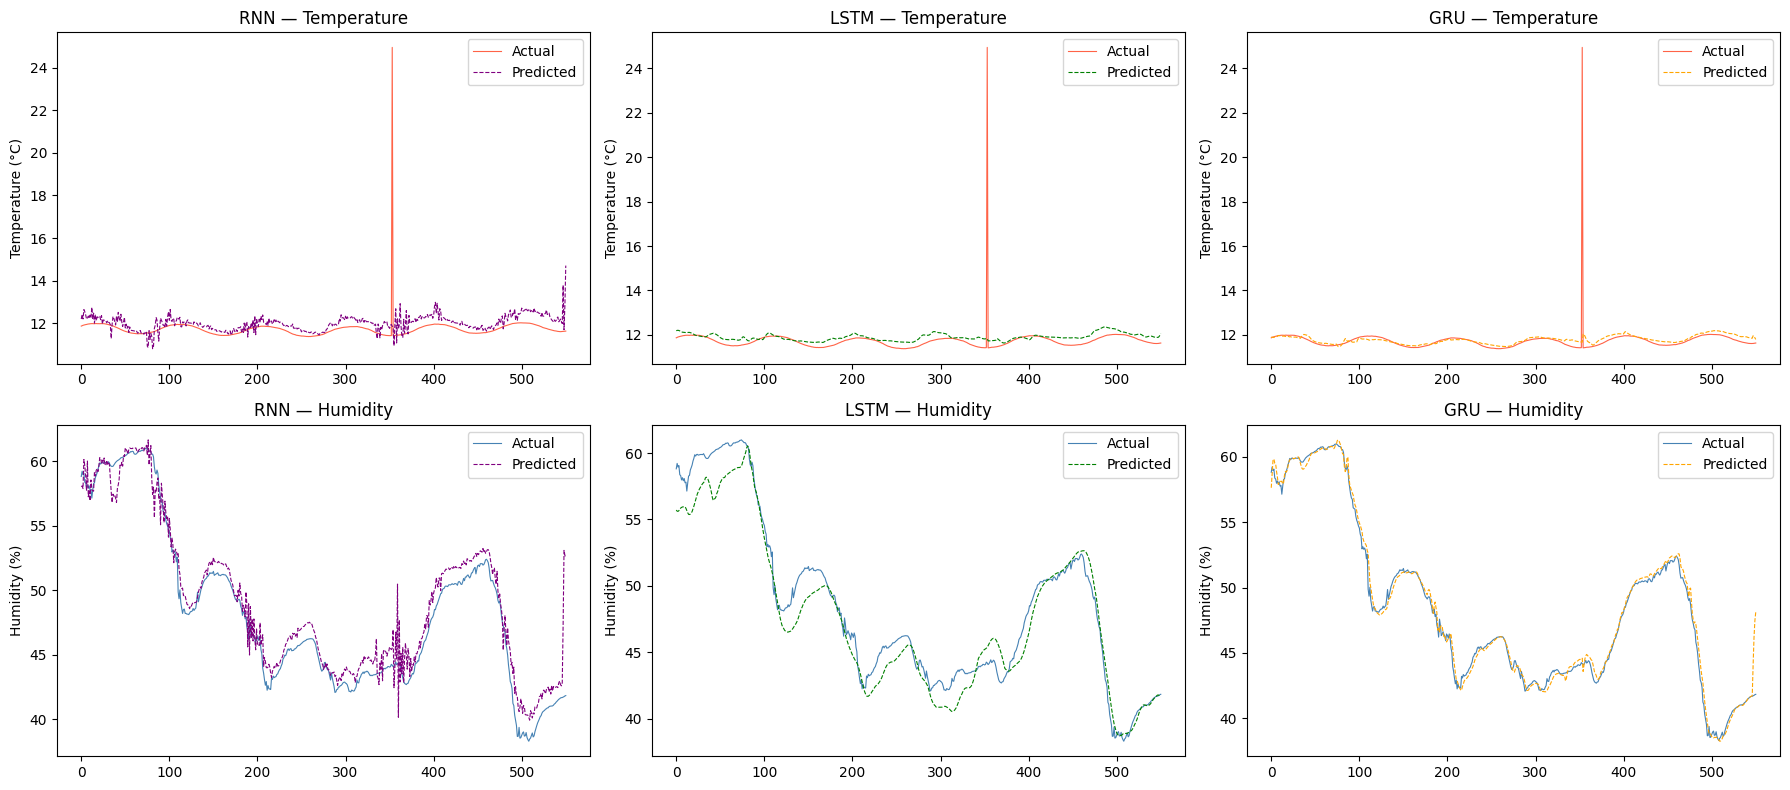

Plot saved.


In [24]:
# Plot predictions vs actual for all 3 models

# Reuse the same inverse scaling from Part 2
temp_min = df['Indoor_temperature_room'].min()
temp_max = df['Indoor_temperature_room'].max()
hum_min  = df['Humidity'].min()
hum_max  = df['Humidity'].max()

def inverse_scale(preds):
    t = preds[:, 0] * (temp_max - temp_min) + temp_min
    h = preds[:, 1] * (hum_max  - hum_min)  + hum_min
    return t, h

true_temp = y_test[:, 0] * (temp_max - temp_min) + temp_min
true_hum  = y_test[:, 1] * (hum_max  - hum_min)  + hum_min

models = [
    ('RNN',  rnn_results['predictions'],  'purple'),
    ('LSTM', lstm_results['predictions'], 'green'),
    ('GRU',  gru_results['predictions'],  'orange')
]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for i, (name, preds, color) in enumerate(models):
    pt, ph = inverse_scale(preds)

    axes[0, i].plot(true_temp, label='Actual', color='tomato', linewidth=0.8)
    axes[0, i].plot(pt, label='Predicted', color=color, linewidth=0.8, linestyle='--')
    axes[0, i].set_title(f'{name} — Temperature')
    axes[0, i].set_ylabel('Temperature (°C)')
    axes[0, i].legend()

    axes[1, i].plot(true_hum, label='Actual', color='steelblue', linewidth=0.8)
    axes[1, i].plot(ph, label='Predicted', color=color, linewidth=0.8, linestyle='--')
    axes[1, i].set_title(f'{name} — Humidity')
    axes[1, i].set_ylabel('Humidity (%)')
    axes[1, i].legend()

plt.tight_layout()
plt.savefig('rnn_lstm_gru_predictions.png', dpi=150)
plt.show()
print("Plot saved.")

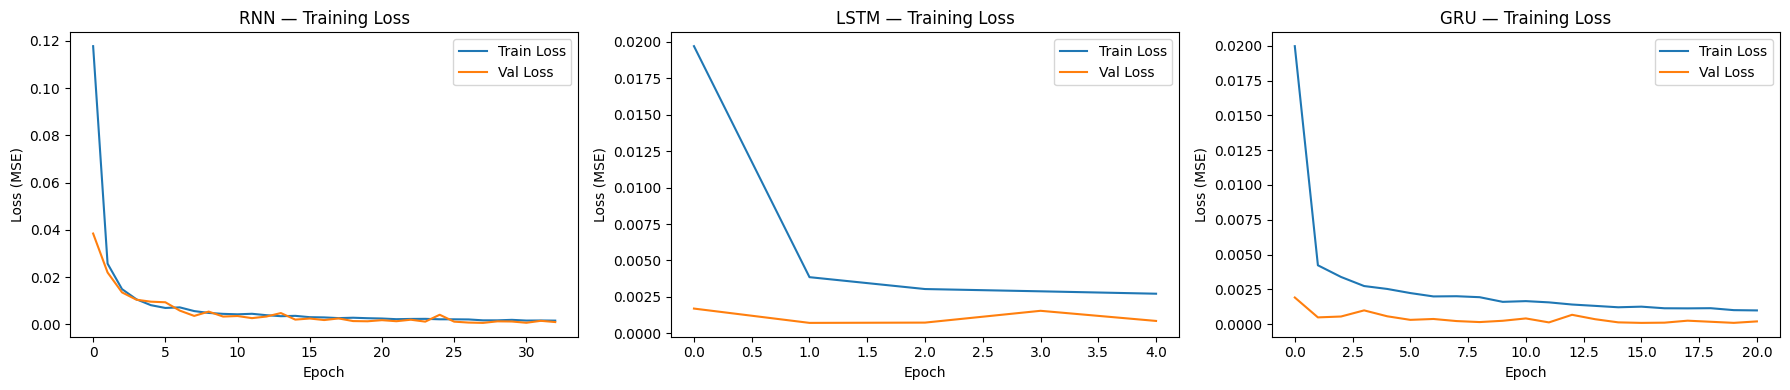

Plot saved.


In [25]:
# Plot training loss curves

# This shows how each model improved during training
# A smooth decreasing curve means healthy training

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, history, name in zip(axes,
                              [rnn_history, lstm_history, gru_history],
                              ['RNN', 'LSTM', 'GRU']):
    ax.plot(history.history['loss'],     label='Train Loss')
    ax.plot(history.history['val_loss'], label='Val Loss')
    ax.set_title(f'{name} — Training Loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (MSE)')
    ax.legend()

plt.tight_layout()
plt.savefig('training_loss.png', dpi=150)
plt.show()
print("Plot saved.")

In [26]:
# PART 4: INTELLIGENT ADAPTIVE CONTROL LOGIC

# Use GRU predictions (best model)
predictions = gru_results['predictions']

# Convert predictions back to real values
temp_min = df['Indoor_temperature_room'].min()
temp_max = df['Indoor_temperature_room'].max()
hum_min  = df['Humidity'].min()
hum_max  = df['Humidity'].max()

pred_temp = predictions[:, 0] * (temp_max - temp_min) + temp_min
pred_hum  = predictions[:, 1] * (hum_max  - hum_min)  + hum_min

print("Predictions ready.")

# Comfort ranges

TEMP_MIN = 18   # °C
TEMP_MAX = 24

HUM_MIN = 30    # %
HUM_MAX = 60

print("Comfort ranges set.")

Predictions ready.
Comfort ranges set.


In [27]:
# Control system simulation

actions = []  # store decisions

heater_active = False
heater_timer = 0
heater_uses_per_day = {}

ventilation_active = False

# Create time index aligned with test set
test_index = df.index[-len(pred_temp):]

for i in range(len(pred_temp)):

    current_time = test_index[i]
    current_day = current_time.date()

    # Initialise daily heater usage
    if current_day not in heater_uses_per_day:
        heater_uses_per_day[current_day] = 0

    temp = pred_temp[i]
    hum  = pred_hum[i]

    action = "Do Nothing"

    # Rule 1: Ventilation (highest priority)
    if temp > TEMP_MAX or hum > HUM_MAX:
        action = "Ventilation ON"
        ventilation_active = True

        # Ventilation cancels heater
        heater_active = False
        heater_timer = 0

    # Rule 2: Heater
    elif temp < TEMP_MIN:
        if heater_uses_per_day[current_day] < 2:
            action = "Heater ON"
            heater_active = True
            heater_timer = 16  # 4 hours = 16 intervals (15 min each)
            heater_uses_per_day[current_day] += 1

    # Maintain heater effect
    if heater_active:
        heater_timer -= 1
        if heater_timer <= 0:
            heater_active = False

    actions.append(action)

print("Control logic simulation complete.")

Control logic simulation complete.


In [28]:
# Combine everything into one table

results_df = pd.DataFrame({
    'Datetime': test_index,
    'Predicted_Temperature': pred_temp,
    'Predicted_Humidity': pred_hum,
    'Action': actions
})

results_df = results_df.set_index('Datetime')

print(results_df.head())

# Save final output

results_df.to_csv('final_predictions_with_control.csv')

print("CSV file saved successfully.")

                     Predicted_Temperature  Predicted_Humidity      Action
Datetime                                                                  
2012-04-05 13:00:00              11.899261           57.628819   Heater ON
2012-04-05 13:15:00              11.897988           58.638817   Heater ON
2012-04-05 13:30:00              11.884186           59.732700  Do Nothing
2012-04-05 13:45:00              11.886502           59.823891  Do Nothing
2012-04-05 14:00:00              11.909357           59.504948  Do Nothing
CSV file saved successfully.


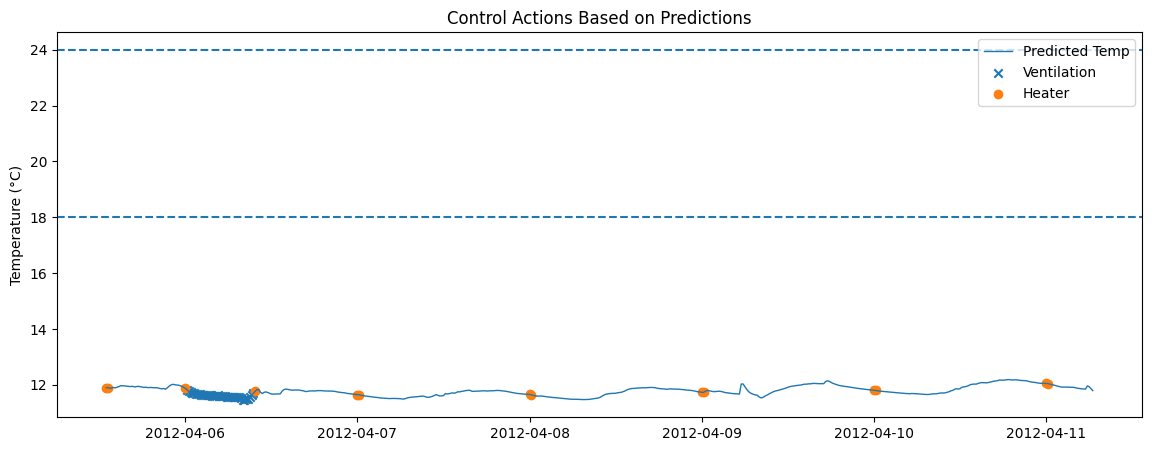

In [29]:
# Plot temperature + actions

plt.figure(figsize=(14, 5))

plt.plot(results_df['Predicted_Temperature'], label='Predicted Temp', linewidth=1)

# Mark actions
vent_idx = results_df['Action'] == "Ventilation ON"
heat_idx = results_df['Action'] == "Heater ON"

plt.scatter(results_df.index[vent_idx],
            results_df['Predicted_Temperature'][vent_idx],
            label='Ventilation', marker='x')

plt.scatter(results_df.index[heat_idx],
            results_df['Predicted_Temperature'][heat_idx],
            label='Heater', marker='o')

plt.axhline(TEMP_MIN, linestyle='--')
plt.axhline(TEMP_MAX, linestyle='--')

plt.title("Control Actions Based on Predictions")
plt.ylabel("Temperature (°C)")
plt.legend()

plt.show()

In [30]:
# PART 5: MODEL COMPARISON AND FINAL EVALUATION


# Create comparison table for all models

comparison_df = pd.DataFrame([
    {
        'Model': 'Linear Regression',
        'Temp MAE': 0.0047,
        'Temp RMSE': 0.0656,
        'Temp R²': -1.3513,
        'Hum MAE': 0.0224,
        'Hum RMSE': 0.1571,
        'Hum R²': 0.3175
    },
    {
        'Model': 'RNN',
        'Temp MAE': 0.0250,
        'Temp RMSE': 0.0539,
        'Temp R²': -0.5874,
        'Hum MAE': 0.0335,
        'Hum RMSE': 0.0523,
        'Hum R²': 0.9244
    },
    {
        'Model': 'LSTM',
        'Temp MAE': 0.0100,
        'Temp RMSE': 0.0420,
        'Temp R²': 0.0345,
        'Hum MAE': 0.0226,
        'Hum RMSE': 0.0323,
        'Hum R²': 0.9712
    },
    {
        'Model': 'GRU',
        'Temp MAE': 0.0228,
        'Temp RMSE': 0.0462,
        'Temp R²': -0.1657,
        'Hum MAE': 0.0156,
        'Hum RMSE': 0.0207,
        'Hum R²': 0.9882
    }
])

print(comparison_df)

               Model  Temp MAE  Temp RMSE  Temp R²  Hum MAE  Hum RMSE  Hum R²
0  Linear Regression    0.0047     0.0656  -1.3513   0.0224    0.1571  0.3175
1                RNN    0.0250     0.0539  -0.5874   0.0335    0.0523  0.9244
2               LSTM    0.0100     0.0420   0.0345   0.0226    0.0323  0.9712
3                GRU    0.0228     0.0462  -0.1657   0.0156    0.0207  0.9882


In [31]:
# Identify best model for each target

best_temp_model = comparison_df.loc[comparison_df['Temp RMSE'].idxmin(), 'Model']
best_hum_model  = comparison_df.loc[comparison_df['Hum RMSE'].idxmin(), 'Model']

print(f"Best temperature model: {best_temp_model}")
print(f"Best humidity model: {best_hum_model}")

Best temperature model: LSTM
Best humidity model: GRU


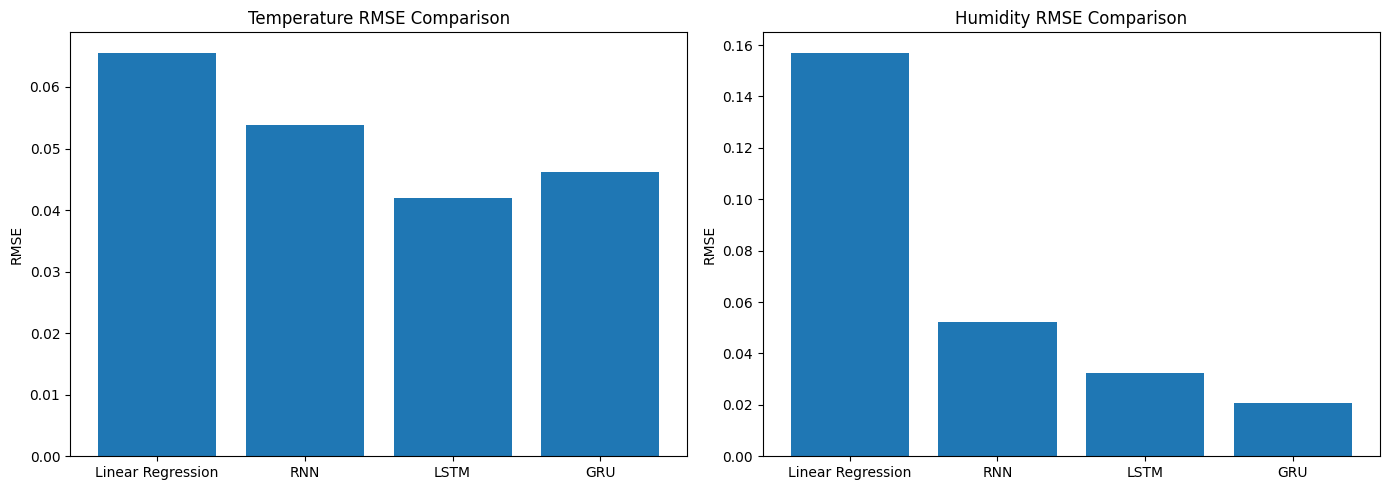

In [32]:
# Plot RMSE comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Temperature RMSE
axes[0].bar(comparison_df['Model'], comparison_df['Temp RMSE'])
axes[0].set_title('Temperature RMSE Comparison')
axes[0].set_ylabel('RMSE')

# Humidity RMSE
axes[1].bar(comparison_df['Model'], comparison_df['Hum RMSE'])
axes[1].set_title('Humidity RMSE Comparison')
axes[1].set_ylabel('RMSE')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

# Final Model Selection Summary
LSTM achieved the best temperature prediction accuracy (RMSE = 0.
0420).

GRU achieved the best humidity prediction accuracy (RMSE = 0.0207).

Linear Regression performed poorly for temperature, confirming that
simple linear models cannot capture the complex time-series behaviour.

RNN improved performance, but LSTM and GRU provided the most reliable results.